# krsim real-scale dynamics — coalescence time distributions

The [first tutorial](https://mrc-ide.github.io/KR_simulator/quickstart.html) walked through every stage on a tiny run so each file could be read by eye. This one uses a more realistic baseline — 100 hosts over 1,000 generations — where the files are too large to inspect directly. Instead it looks at the **distributions** that come out of the genealogy:

- how long ago pairs of strains share a common ancestor (their coalescence time), across the whole genome;
- what fraction of the genome has coalesced by each generation back in time, and how this differs for strains in the same host versus different hosts;
- how many distinct ancestral lineages remain as we go back in time;
- how coalescence varies along the genome, and for one pair of strains along a single chromosome, alongside the SNPs that separate them;
- how each parameter shapes these distributions, and in particular what superinfection does.

Most of this only needs Stage 1 (`krsim simulate`): coalescence times are read straight from the tree sequence. Stage 2 (`krsim mutate`) is used once, to place SNPs on a stretch of chromosome.

This notebook runs in **Google Colab**: run the first cell, which installs krsim, then run the rest with **Runtime → Run all**. To run it on your own computer instead, open it with the `krsim` environment active (see [Installation](https://mrc-ide.github.io/KR_simulator/installation.html)).

In [ ]:
# On Google Colab, install krsim first (about 30 seconds). On your own computer this does nothing.
import subprocess, sys
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "git+https://github.com/mrc-ide/KR_simulator.git"], check=True)

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tskit

from krsim.sim.params import COMP_BREAKPOINTS, GENOME_LENGTH

OUT = "output"

# colours for the plots
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "lines.linewidth": 2,
})

## Baseline parameters

| Parameter | Value | Meaning |
|---|---|---|
| `Nh` | 100 | human hosts |
| `T` | 1000 | generations simulated |
| `K` | 10 | parasites passed on per bite |
| `chi` | 0.2 | superinfection probability |
| `C` | 3 | oocysts per mosquito |

Recombination uses the default *P. falciparum* rate (`7.4e-7` per bp per generation) over the full 14-chromosome genome. Change the values below and re-run the notebook to compare.

In [2]:
NH, T, K, CHI, C = 100, 1000, 10, 0.2, 3
SEED = 42

## Simulate

On a laptop this takes about 30 seconds and up to 3 GB of memory.

In [3]:
start = time.time()
!krsim simulate --Nh {NH} --T {T} --K {K} --chi {CHI} --C {C} --random_seed {SEED} --output_dir {OUT}
print(f"simulate took {time.time() - start:.1f} s")

  wrote  output/ts_42.trees
  wrote  output/sim_ind_node_map_42.csv
  done in 28.3 s



simulate took 29.7 s


The sampled strains are the parasites in the current generation (`time == 0`). Each host carries several strains, and the genome is split into many trees, one for each stretch between recombination breakpoints.

In [4]:
ts = tskit.load(f"{OUT}/ts_{SEED}.trees")

hosts = pd.read_csv(f"{OUT}/sim_ind_node_map_{SEED}.csv")
current = hosts[hosts["time"] == 0]
host_strains = [g["node_id"].to_numpy() for _, g in current.groupby("ind_id")]
strains_per_host = np.array([len(s) for s in host_strains])

n_pairs = ts.num_samples * (ts.num_samples - 1) // 2
print(f"{len(host_strains)} hosts carrying {ts.num_samples} strains "
      f"({strains_per_host.min()}–{strains_per_host.max()} per host)")
print(f"{n_pairs:,} strain pairs, {ts.num_trees:,} trees along the genome")

100 hosts carrying 1150 strains (10–20 per host)
660,675 strain pairs, 28,773 trees along the genome


**Why not `krsim coal-mut`?** The first tutorial's `coal-mut` helper writes `coal_T_<seed>.csv`, with one row per strain pair per tree. That is fine for a small run, but here it would be roughly (number of pairs) × (number of trees) rows, far too many to write out. Instead, tskit's [`pair_coalescence_counts`](https://tskit.dev/tskit/docs/stable/python-api.html#tskit.TreeSequence.pair_coalescence_counts) computes the same information already summarised: for each time window, the fraction of (strain pair × genome) whose common ancestor falls in that window. It takes well under a second.

## Pairwise coalescence time distribution

For a pair of strains at one position in the genome, the **coalescence time** is how many generations back their two lineages meet in a common ancestor. Recombination means this differs along the genome, so we average over every position and every pair of strains.

Coalescence is computed in one-generation time windows and shown in 10-generation bins. The simulation starts from unrelated founder genomes `T` generations ago, so a pair whose lineages have not met by then never coalesces in the simulation; with 1,000 generations this is a tiny share of the genome.

The spikes are real: when one ancestral strain is transmitted widely, many pairs share it as their common ancestor at once, over long stretches of genome.

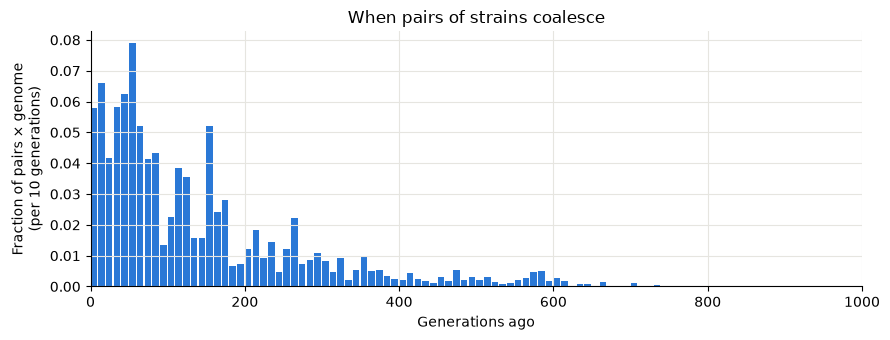

coalesced within 1000 generations: 100.0% of pairs × genome
not coalesced (lineages trace back to different founders): 0.03%
mean pairwise coalescence time: 140 generations


In [5]:
# one-generation time windows [t, t+1); the last window catches the founders at time T
time_windows = np.append(np.arange(T + 1), np.inf).astype(float)
generations = time_windows[:-1]

# fraction of all (strain pair x genome) coalescing in each window
coal_dist = ts.pair_coalescence_counts(time_windows=time_windows, pair_normalise=True)
not_coalesced = 1 - coal_dist.sum()

BIN = 10
binned = coal_dist[:T].reshape(-1, BIN).sum(axis=1)

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(np.arange(0, T, BIN), binned, width=BIN * 0.85, align="edge", color=BLUE)
ax.set_xlabel("Generations ago")
ax.set_ylabel(f"Fraction of pairs × genome\n(per {BIN} generations)")
ax.set_title("When pairs of strains coalesce")
ax.set_xlim(0, T)
plt.tight_layout()
plt.show()

print(f"coalesced within {T} generations: {coal_dist.sum():.1%} of pairs × genome")
print(f"not coalesced (lineages trace back to different founders): {not_coalesced:.2%}")
print(f"mean pairwise coalescence time: {(generations * coal_dist).sum() / coal_dist.sum():.0f} generations")

## Fraction of the genome coalesced over time

The cumulative version of the distribution above: for a random pair of strains, what fraction of their genome has found a common ancestor within `t` generations.

The time axis is logarithmic so the first few generations, where most of the action is for strains in the same host, are visible.

Strains in the same host often arrived together from one mosquito bite, so they tend to be close relatives (siblings from the same oocyst, or cotransmitted from the previous host). Strains in different hosts are usually more distantly related. `pair_coalescence_counts` can count pairs within each host separately, and the between-host pairs are what is left over.

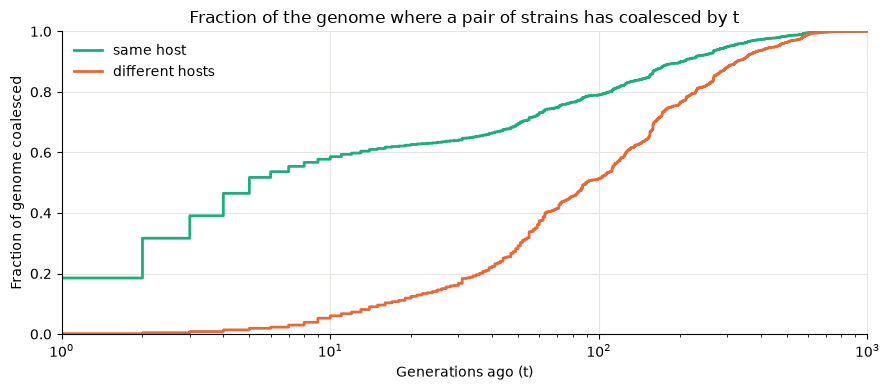

6,675 same-host pairs, 654,000 different-host pairs (so 'all pairs' is almost identical to 'different hosts')


,all pairs,same host,different hosts
within t generations,,,
1,0.3%,18.5%,0.1%
2,0.7%,31.7%,0.4%
5,2.4%,51.7%,1.9%
10,6.6%,58.6%,6.0%
50,29.6%,69.6%,29.2%
100,51.6%,79.0%,51.4%
500,96.4%,98.4%,96.4%
1000,100.0%,100.0%,100.0%


In [6]:
all_counts = ts.pair_coalescence_counts(time_windows=time_windows)

# pairs within each host: one index (i, i) per host, summed over hosts
within_counts = ts.pair_coalescence_counts(
    sample_sets=host_strains,
    indexes=[(i, i) for i in range(len(host_strains))],
    time_windows=time_windows,
).sum(axis=0)
n_within = int((strains_per_host * (strains_per_host - 1) // 2).sum())
n_between = n_pairs - n_within

cumulative = pd.DataFrame({
    "all pairs": np.cumsum(all_counts) / n_pairs,
    "same host": np.cumsum(within_counts) / n_within,
    "different hosts": np.cumsum(all_counts - within_counts) / n_between,
}, index=pd.Index(generations.astype(int), name="within t generations"))

fig, ax = plt.subplots(figsize=(9, 4))
for label, colour in [("same host", AQUA), ("different hosts", ORANGE)]:
    ax.step(cumulative.index, cumulative[label], where="post", color=colour, label=label)
ax.set_xlabel("Generations ago (t)")
ax.set_ylabel("Fraction of genome coalesced")
ax.set_title("Fraction of the genome where a pair of strains has coalesced by t")
ax.set_xscale("log")
ax.set_xlim(1, T)
ax.set_ylim(0, 1)
ax.legend(loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

print(f"{n_within:,} same-host pairs, {n_between:,} different-host pairs "
      f"(so 'all pairs' is almost identical to 'different hosts')")
cumulative.loc[[1, 2, 5, 10, 50, 100, 500, T]].style.format("{:.1%}")

### Same-host and different-host distributions

The same split as a distribution rather than a running total. The first histogram above is all pairs, and about 99% of pairs are in different hosts, so it is essentially the different-host distribution. Here each group is normalised on its own. The time axis is logarithmic, with bins that widen going back in time.

same host: median 5, mean 62 generations
different hosts: median 90, mean 141 generations


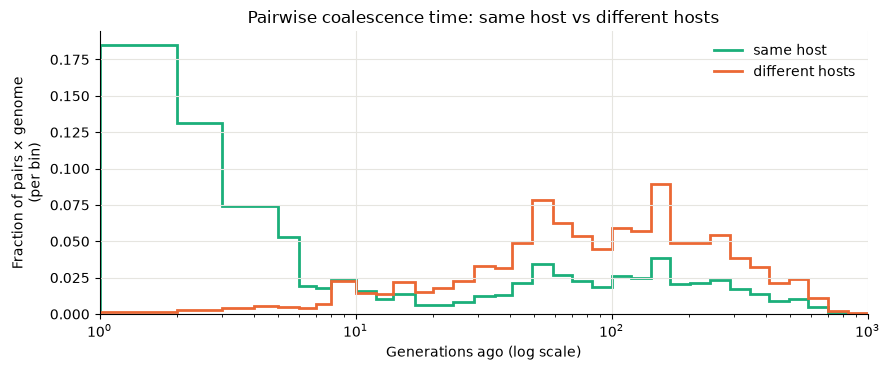

In [7]:
within_dist = within_counts / n_within
between_dist = (all_counts - within_counts) / n_between

# log-spaced bins of whole generations, from 1 to T
log_bins = np.unique(np.round(np.geomspace(1, T + 1, 40)).astype(int))

fig, ax = plt.subplots(figsize=(9, 3.8))
for label, dist, colour in [("same host", within_dist, AQUA), ("different hosts", between_dist, ORANGE)]:
    ax.stairs(np.add.reduceat(dist[:T + 1], log_bins[:-1])[: len(log_bins) - 1], log_bins,
              color=colour, linewidth=2, label=label)
    median = np.searchsorted(np.cumsum(dist) / dist.sum(), 0.5)
    mean = (generations * dist).sum() / dist.sum()
    print(f"{label}: median {median}, mean {mean:.0f} generations")
ax.set_xscale("log")
ax.set_xlim(1, T)
ax.set_xlabel("Generations ago (log scale)")
ax.set_ylabel("Fraction of pairs × genome\n(per bin)")
ax.set_title("Pairwise coalescence time: same host vs different hosts")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## Ancestral lineages through time

Going back in time, the sampled strains' lineages merge, so fewer distinct ancestors are left. At each generation `t` we count, at every position, how many separate lineages remain, and average over the genome. At `t = 0` this is the number of sampled strains; it falls to 1 once every strain at that position shares one common ancestor.

The second panel follows that last step: the fraction of the genome where **all** strains have found a single common ancestor (the whole-sample MRCA) by generation `t`.

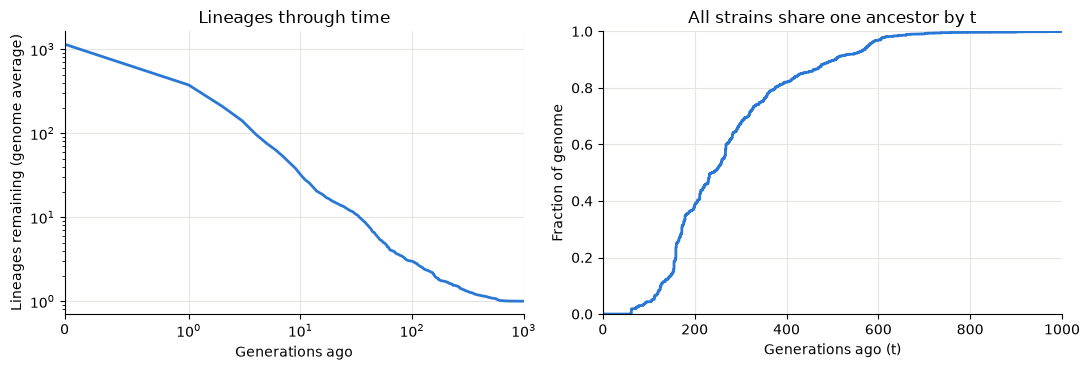

fully coalesced within 1000 generations: 99.9% of the genome
half the genome is fully coalesced by generation 238


In [8]:
# a lineage is present at time t on each branch (edge) spanning t, plus each
# tree root at or below t (the lineage carries on above it), weighted by span
edges = ts.tables.edges
child_time, parent_time = ts.nodes_time[edges.child], ts.nodes_time[edges.parent]
edge_span = edges.right - edges.left

root_time, root_span = [], []
for tree in ts.trees():
    for root in tree.roots:
        root_time.append(tree.time(root))
        root_span.append(tree.span)
root_time, root_span = np.array(root_time), np.array(root_span)

lineages = np.array([
    edge_span[(child_time <= t) & (parent_time > t)].sum() + root_span[root_time <= t].sum()
    for t in range(T + 1)
]) / ts.sequence_length

# whole-sample MRCA of each tree with a single root. The root is a founder at
# time T, often above a long single-child branch, so walk down from it to the
# first node where lineages actually merge.
mrca_time, mrca_span = [], []
for tree in ts.trees():
    if tree.num_roots != 1:
        continue
    u = tree.root
    while tree.num_children(u) == 1:
        u = tree.left_child(u)
    mrca_time.append(tree.time(u))
    mrca_span.append(tree.span)
mrca_time, mrca_span = np.array(mrca_time), np.array(mrca_span)
fully_coalesced = np.array([mrca_span[mrca_time <= t].sum() for t in range(T + 1)]) / ts.sequence_length

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot(range(T + 1), lineages, color=BLUE)
ax1.set_xscale("symlog", linthresh=1)
ax1.set_yscale("log")
ax1.set_xlim(0, T)
ax1.set_xlabel("Generations ago")
ax1.set_ylabel("Lineages remaining (genome average)")
ax1.set_title("Lineages through time")

ax2.step(range(T + 1), fully_coalesced, where="post", color=BLUE)
ax2.set_xlim(0, T)
ax2.set_ylim(0, 1)
ax2.set_xlabel("Generations ago (t)")
ax2.set_ylabel("Fraction of genome")
ax2.set_title("All strains share one ancestor by t")
plt.tight_layout()
plt.show()

print(f"fully coalesced within {T} generations: {fully_coalesced[-1]:.1%} of the genome")
if fully_coalesced[-1] >= 0.5:
    print(f"half the genome is fully coalesced by generation {np.searchsorted(fully_coalesced, 0.5)}")

## Coalescence along the genome

Recombination breaks the genome into pieces with their own histories, so some regions coalesce much faster than others. Here the genome is split into 500 equal windows (about 47 kb each), and in each one we find the median coalescence time over all strain pairs, with the shaded band from the 25th to the 75th percentile. Grey lines mark chromosome boundaries.

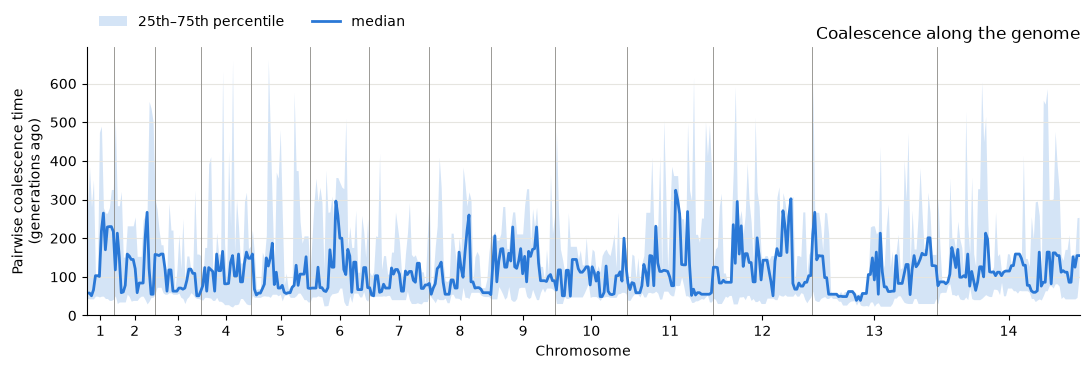

median coalescence time ranges from 39 to 324 generations across windows


In [9]:
n_windows = 500
genome_windows = np.linspace(0, ts.sequence_length, n_windows + 1)
q25, q50, q75 = ts.pair_coalescence_quantiles(
    windows=genome_windows, quantiles=np.array([0.25, 0.5, 0.75])
).T

mid_mb = (genome_windows[:-1] + genome_windows[1:]) / 2 / 1e6
chr_edges = np.concatenate(([0], COMP_BREAKPOINTS, [GENOME_LENGTH])) / 1e6

fig, ax = plt.subplots(figsize=(11, 3.8))
for x in chr_edges[1:-1]:
    ax.axvline(x, color=GREY, linewidth=0.6)
ax.fill_between(mid_mb, q25, q75, color=BLUE, alpha=0.2, linewidth=0, label="25th–75th percentile")
ax.plot(mid_mb, q50, color=BLUE, label="median")
ax.set_xticks((chr_edges[:-1] + chr_edges[1:]) / 2)
ax.set_xticklabels(range(1, len(chr_edges)))
ax.grid(axis="x", visible=False)
ax.set_xlim(0, chr_edges[-1])
ax.set_ylim(0, None)
ax.set_xlabel("Chromosome")
ax.set_ylabel("Pairwise coalescence time\n(generations ago)")
ax.set_title("Coalescence along the genome", loc="right")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02), frameon=False, ncol=2)
plt.tight_layout()
plt.show()

print(f"median coalescence time ranges from {np.nanmin(q50):.0f} to {np.nanmax(q50):.0f} "
      f"generations across windows")

### One pair of strains along a chromosome

The plot above summarises all pairs. Here we follow a single pair of strains along one chromosome, or a stretch of it, and add the mutations that separate them. Set the chromosome and interval (positions in base pairs along that chromosome) in the first lines.

To place mutations on the genealogy, run Stage 2 once:

In [10]:
!krsim mutate --ts {OUT}/ts_{SEED}.trees --random_seed {SEED} --output_dir {OUT}
ts_mut = tskit.load(f"{OUT}/ts_mut_{SEED}.trees")

  wrote  output/ts_mut_42.trees
  done in 0.1 s



The blue step line is the pair's coalescence time: it changes at recombination breakpoints. Each grey line is a **heterozygous SNP**, a site where the two strains carry different alleles. Where the pair coalesced recently there has been little time for mutations to separate them, so het SNPs are rare; where their common ancestor is old, they are dense.

The pair is picked automatically: a pair from the same host that coalesced within 10 generations on about half of the chromosome, so both patterns show. Set `PAIR = (strain_a, strain_b)` to choose your own.

In [11]:
CHROM = 1
START, END = 0, None  # bp along the chromosome; None = to the end of the chromosome
PAIR = None           # e.g. (1090, 1096); None picks a pair automatically

chr_edges_bp = np.concatenate(([0], COMP_BREAKPOINTS, [GENOME_LENGTH]))
chr_offset = chr_edges_bp[CHROM - 1]
chr_length = chr_edges_bp[CHROM] - chr_offset

def pair_coal_times(a, b, left, right):
    """Breakpoints and coalescence times of strains a and b along [left, right) (genome coordinates)."""
    breaks, times = [left], []
    for tree in ts_mut.trees():
        l, r = tree.interval
        if r <= left:
            continue
        if l >= right:
            break
        mrca = tree.mrca(a, b)
        t = tree.time(mrca) if mrca != tskit.NULL else np.nan
        if times and t == times[-1]:
            breaks[-1] = min(r, right)  # neighbouring trees with the same time: one step
        else:
            times.append(t)
            breaks.append(min(r, right))
    return np.array(breaks), np.array(times)

def het_snps(a, b, left, right):
    """Positions where strains a and b carry different alleles."""
    return np.array([
        v.site.position for v in ts_mut.variants(samples=[a, b], left=left, right=right)
        if (v.genotypes[0] > 0) != (v.genotypes[1] > 0)
    ])

if PAIR is None:
    # same-host pair recently related (<= 10 generations) on closest to half the chromosome
    chr_left, chr_right = chr_offset, chr_offset + chr_length
    best = None
    for strains in host_strains:
        for i, a in enumerate(strains):
            for b in strains[i + 1:]:
                breaks, times = pair_coal_times(a, b, chr_left, chr_right)
                recent = (np.diff(breaks) * (times <= 10)).sum() / chr_length
                if best is None or abs(recent - 0.5) < best[0]:
                    best = (abs(recent - 0.5), (a, b))
    PAIR = best[1]
print(f"strains {PAIR[0]} and {PAIR[1]}")

strains 1090 and 1096


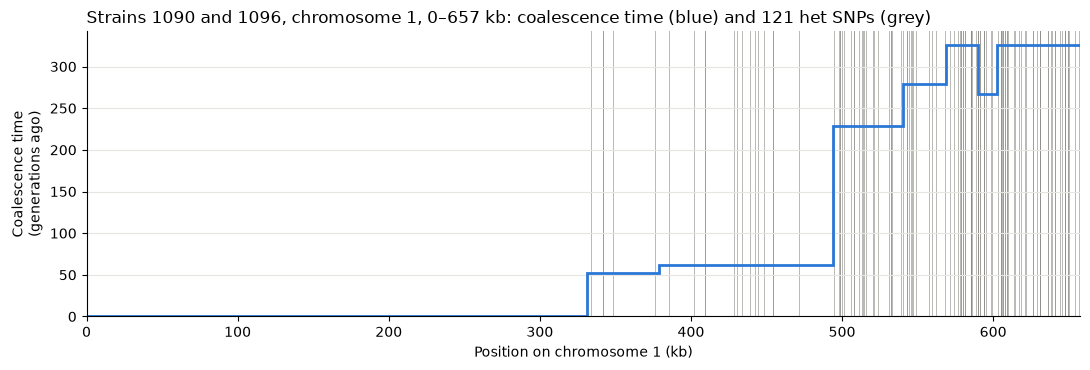

In [12]:
def plot_pair(a, b, start, end):
    end = chr_length if end is None else end
    left, right = chr_offset + start, chr_offset + end
    breaks, times = pair_coal_times(a, b, left, right)
    het = het_snps(a, b, left, right)

    fig, ax = plt.subplots(figsize=(11, 3.8))
    for x in (het - chr_offset) / 1e3:
        ax.axvline(x, color=GREY, linewidth=0.7, alpha=0.6, zorder=1)
    ax.stairs(times, (breaks - chr_offset) / 1e3, color=BLUE, linewidth=2, baseline=None, zorder=2)
    ax.set_xlim(start / 1e3, end / 1e3)
    ax.set_ylim(0, None)
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(f"Position on chromosome {CHROM} (kb)")
    ax.set_ylabel("Coalescence time\n(generations ago)")
    ax.set_title(f"Strains {a} and {b}, chromosome {CHROM}, {start / 1e3:.0f}–{end / 1e3:.0f} kb: "
                 f"coalescence time (blue) and {len(het)} het SNPs (grey)", loc="left")
    plt.tight_layout()
    plt.show()

plot_pair(*PAIR, START, END)

Zoom in on a shorter interval:

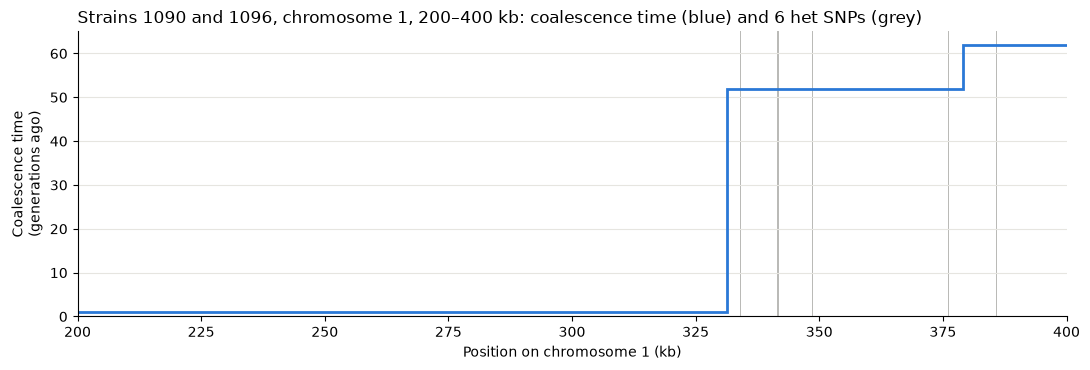

In [13]:
plot_pair(*PAIR, 200_000, 400_000)

## Variation between runs

A single run is one random realisation. Re-running with different seeds shows how much the distribution changes by chance alone. Each run takes about 30 seconds; the timings are printed. Add more seeds to `REPLICATE_SEEDS` for a fuller picture.

seed 1: 29.8 s, 1210 strains, 32,960 trees, 99.8% coalesced by T


seed 2: 31.0 s, 1170 strains, 31,361 trees, 99.9% coalesced by T


seed 3: 31.1 s, 1180 strains, 30,701 trees, 100.0% coalesced by T


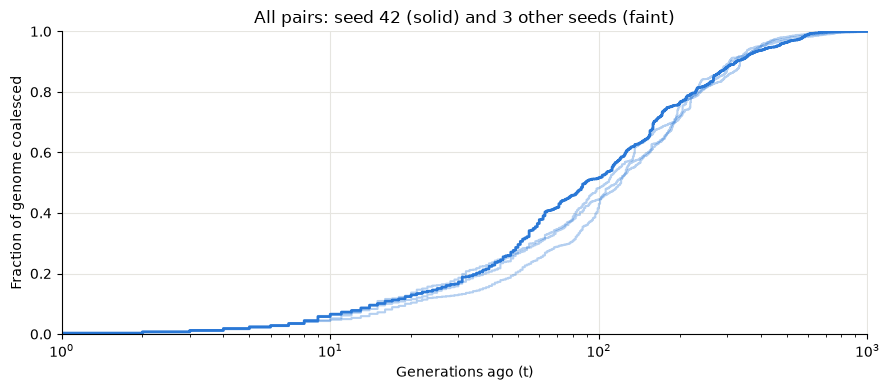

In [14]:
REPLICATE_SEEDS = [1, 2, 3]

fig, ax = plt.subplots(figsize=(9, 4))
for seed in REPLICATE_SEEDS:
    start = time.time()
    !krsim simulate --Nh {NH} --T {T} --K {K} --chi {CHI} --C {C} --random_seed {seed} --output_dir {OUT} > /dev/null 2>&1
    rep = tskit.load(f"{OUT}/ts_{seed}.trees")
    frac = np.cumsum(rep.pair_coalescence_counts(time_windows=time_windows, pair_normalise=True))
    ax.step(generations, frac, where="post", color=BLUE, alpha=0.35, linewidth=1.5)
    print(f"seed {seed}: {time.time() - start:.1f} s, "
          f"{rep.num_samples} strains, {rep.num_trees:,} trees, {frac[-1]:.1%} coalesced by T")

ax.step(cumulative.index, cumulative["all pairs"], where="post", color=BLUE, label=f"seed {SEED}")
ax.set_xlabel("Generations ago (t)")
ax.set_ylabel("Fraction of genome coalesced")
ax.set_title(f"All pairs: seed {SEED} (solid) and {len(REPLICATE_SEEDS)} other seeds (faint)")
ax.set_xscale("log")
ax.set_xlim(1, T)
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

## Varying the parameters

To see what each parameter does, we vary one at a time around the baseline, with three values each, and keep the others fixed. That is 10 extra simulations. They run in parallel, `N_PARALLEL` at a time (each needs up to about 3 GB of memory, and about 6 GB for 200 hosts), and take roughly 2 minutes in total. Lower `N_PARALLEL` on a machine with less memory.

In [15]:
import subprocess
from concurrent.futures import ThreadPoolExecutor

SWEEP = {
    "Nh":  [50, 100, 200],
    "T":   [250, 500, 1000],
    "K":   [5, 10, 20],
    "chi": [0.05, 0.2, 0.5],
    "C":   [1, 3, 5],
}
N_PARALLEL = 4
BASELINE = {"Nh": NH, "T": T, "K": K, "chi": CHI, "C": C}

def run_dir(param, value):
    """Output folder for a run; the baseline itself is the main run above."""
    return OUT if value == BASELINE[param] else f"{OUT}/sweep/{param}_{value}"

def simulate(param, value):
    params = {**BASELINE, param: value}
    start = time.time()
    subprocess.run(
        ["krsim", "simulate", "--Nh", str(params["Nh"]), "--T", str(params["T"]), "--K", str(params["K"]),
         "--chi", str(params["chi"]), "--C", str(params["C"]), "--random_seed", str(SEED),
         "--output_dir", run_dir(param, value)],
        check=True, capture_output=True,
    )
    return f"{param} = {value}: {time.time() - start:.0f} s"

jobs = [(p, v) for p, values in SWEEP.items() for v in values if v != BASELINE[p]]
start = time.time()
with ThreadPoolExecutor(N_PARALLEL) as pool:
    for message in pool.map(lambda job: simulate(*job), jobs):
        print(message)
print(f"all {len(jobs)} runs: {time.time() - start:.0f} s")

Nh = 50: 18 s


Nh = 200: 72 s
T = 250: 9 s
T = 500: 18 s
K = 5: 26 s


K = 20: 59 s
chi = 0.05: 33 s


chi = 0.5: 43 s
C = 1: 27 s


C = 5: 40 s
all 10 runs: 112 s


For every run we compute the same-host and different-host coalescence counts, as earlier, and plot the fraction of the genome coalesced by each generation. Light to dark is low to high values of the parameter.

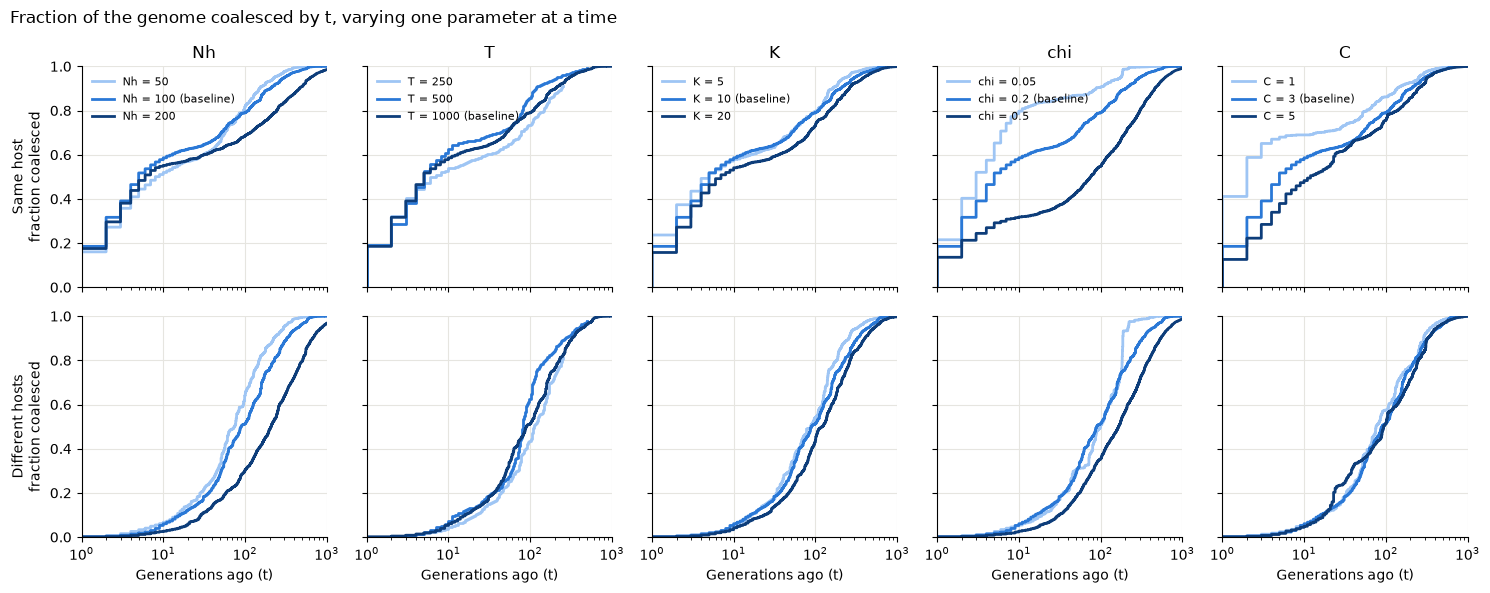

In [16]:
def same_and_different_host(run_ts, run_hosts, windows=None):
    """Fraction of (pair x genome) coalescing in each generation, for same-host and different-host pairs."""
    run_T = int(run_ts.max_root_time)
    tw = np.append(np.arange(run_T + 1), np.inf).astype(float)
    total = run_ts.pair_coalescence_counts(time_windows=tw, windows=windows)
    within = run_ts.pair_coalescence_counts(
        sample_sets=run_hosts, indexes=[(i, i) for i in range(len(run_hosts))],
        time_windows=tw, windows=windows,
    ).sum(axis=-2)
    sizes = np.array([len(s) for s in run_hosts])
    n_same = (sizes * (sizes - 1) // 2).sum()
    n_all = run_ts.num_samples * (run_ts.num_samples - 1) // 2
    return within / n_same, (total - within) / (n_all - n_same)

def load_run(folder):
    run_ts = tskit.load(f"{folder}/ts_{SEED}.trees")
    run_map = pd.read_csv(f"{folder}/sim_ind_node_map_{SEED}.csv")
    run_hosts = [g["node_id"].to_numpy() for _, g in run_map[run_map["time"] == 0].groupby("ind_id")]
    return run_ts, run_hosts

RAMP = ["#9ec5f4", "#2a78d6", "#0d3d7a"]  # light -> dark = low -> high

fig, axes = plt.subplots(2, len(SWEEP), figsize=(15, 6), sharex=True, sharey=True)
rows = []
for j, (param, values) in enumerate(SWEEP.items()):
    for value, colour in zip(values, RAMP):
        same, different = same_and_different_host(*load_run(run_dir(param, value)))
        g = np.arange(len(same))
        label = f"{param} = {value}" + (" (baseline)" if value == BASELINE[param] else "")
        axes[0, j].step(g, np.cumsum(same), where="post", color=colour, label=label)
        axes[1, j].step(g, np.cumsum(different), where="post", color=colour, label=label)
        rows.append({"parameter": param, "value": str(value),
                     "same host, by 10": np.cumsum(same)[10], "same host, by 100": np.cumsum(same)[100],
                     "different hosts, by 10": np.cumsum(different)[10],
                     "different hosts, by 100": np.cumsum(different)[100]})
    axes[0, j].set_title(param)
    axes[0, j].legend(frameon=False, fontsize=8, loc="upper left")
for ax in axes.flat:
    ax.set_xscale("log")
    ax.set_xlim(1, max(SWEEP["T"]))
    ax.set_ylim(0, 1)
axes[0, 0].set_ylabel("Same host\nfraction coalesced")
axes[1, 0].set_ylabel("Different hosts\nfraction coalesced")
for ax in axes[1]:
    ax.set_xlabel("Generations ago (t)")
fig.suptitle("Fraction of the genome coalesced by t, varying one parameter at a time", x=0.01, ha="left")
plt.tight_layout()
plt.show()

pd.DataFrame(rows).set_index(["parameter", "value"]).style.format("{:.0%}")

Superinfection (`chi`) and oocysts per mosquito (`C`) mostly change how related strains in the **same host** are: more superinfection brings in unrelated strains, and more oocysts make cotransmitted strains less likely to be siblings. The number of hosts (`Nh`) mostly changes **different-host** pairs: a larger population takes longer to coalesce.

### Low and high superinfection along the genome

The median coalescence time in each genome window, as in the earlier plot, for the lowest and highest `chi` in the sweep, split into same-host and different-host pairs. The time axis is linear up to 10 generations and logarithmic above.

chi = 0.05: genome-average median 3 generations (same host), 115 (different hosts)


chi = 0.5: genome-average median 82 generations (same host), 181 (different hosts)


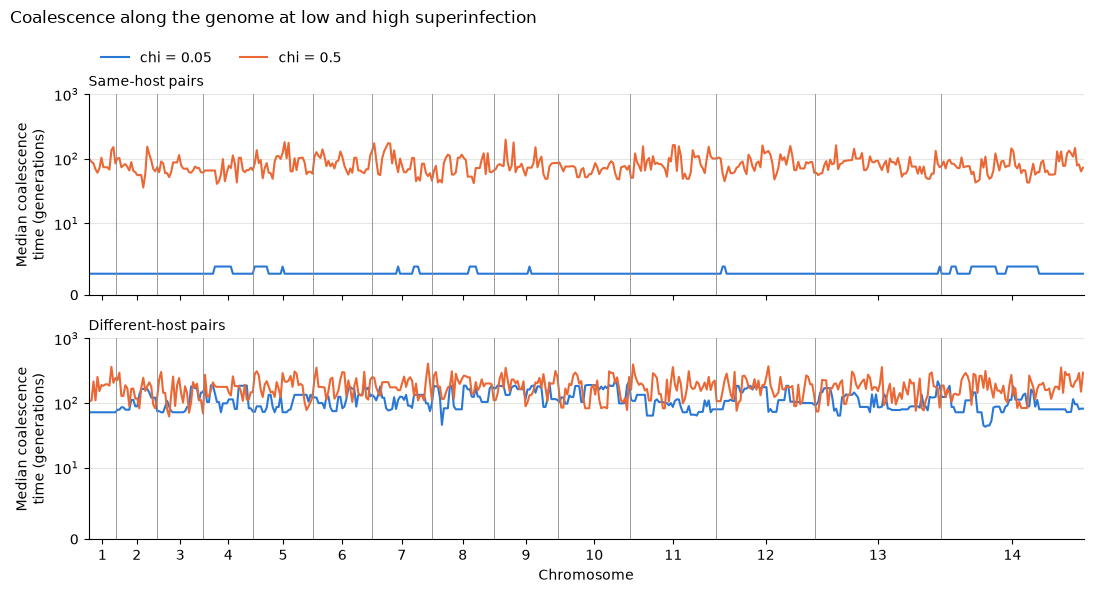

In [17]:
low_chi, high_chi = min(SWEEP["chi"]), max(SWEEP["chi"])

def median_by_window(counts):
    """Median coalescence generation in each genome window, from (window, generation) counts."""
    cdf = np.cumsum(counts, axis=1) / counts.sum(axis=1, keepdims=True)
    return (cdf < 0.5).sum(axis=1)

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, sharey=True)
for value, colour in [(low_chi, BLUE), (high_chi, ORANGE)]:
    same, different = same_and_different_host(*load_run(run_dir("chi", value)), windows=genome_windows)
    label = f"chi = {value}"
    axes[0].plot(mid_mb, median_by_window(same), color=colour, linewidth=1.5, label=label)
    axes[1].plot(mid_mb, median_by_window(different), color=colour, linewidth=1.5, label=label)
    print(f"{label}: genome-average median {median_by_window(same).mean():.0f} generations (same host), "
          f"{median_by_window(different).mean():.0f} (different hosts)")
for ax, title in zip(axes, ["Same-host pairs", "Different-host pairs"]):
    for x in chr_edges[1:-1]:
        ax.axvline(x, color=GREY, linewidth=0.6)
    ax.grid(axis="x", visible=False)
    ax.set_yscale("symlog", linthresh=10)
    ax.set_ylim(0, max(SWEEP["T"]))
    ax.set_ylabel("Median coalescence\ntime (generations)")
    ax.set_title(title, loc="left", fontsize=10)
axes[1].set_xticks((chr_edges[:-1] + chr_edges[1:]) / 2)
axes[1].set_xticklabels(range(1, len(chr_edges)))
axes[1].set_xlim(0, chr_edges[-1])
axes[1].set_xlabel("Chromosome")
axes[0].legend(loc="lower left", bbox_to_anchor=(0, 1.08), frameon=False, ncol=2)
fig.suptitle("Coalescence along the genome at low and high superinfection", x=0.01, ha="left")
plt.tight_layout()
plt.show()

## Next steps

- Change `NH`, `T`, `K`, `CHI` or `C` at the top, or the values in `SWEEP`, and re-run to explore other parts of parameter space.
- `pair_coalescence_counts` also accepts `sample_sets` and `indexes` for any grouping of strains you choose (see the [tskit docs](https://tskit.dev/tskit/docs/stable/python-api.html#tskit.TreeSequence.pair_coalescence_counts)).
- To compare against genetic data, continue from `ts_<seed>.trees` with `krsim mutate`, `vcf-strain` and `vcf-host`, as in the [first tutorial](https://mrc-ide.github.io/KR_simulator/quickstart.html).